In [29]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as fit
from scipy.signal import periodogram
sys.path.append("../")
from analysis import System
import gc
import os

def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

In [4]:
masks = ["no", "0.38", "0.54", "0.70"]
norm = ["52mW_Pin", "1mW_Pout"]
voltages = ["10"]
# for i in np.linspace(0, 10, 21):
#     if 2 * i % 2 == 0:
#         voltages.append(str(int(i)))
#     else:
#         voltages.append(str(i))
# l = System("michelson", [f"../../data/20261017/{k}mask_{w}_{j}V/iter_{i}.tdms" for w in norm for k in masks for j in voltages for i in range(0, 20) if ((k != "no" and k != "0.70") or (k == "no" and (j == "0" or j == "10" or j == "9.5" or j == "9") and w != "1mW_Pout") or (k == "0.70" and w != "52mW_Pin"))], set_data = True, channel = "X")
l = System("michelson", [f"../../data/20261017/{k}mask_{norm[0]}_{j}V/iter_{i}.tdms" 
    if k != "0.70"
    else f"../../data/20261017/{k}mask_{norm[1]}_{j}V/iter_{i}.tdms" 
    if k == "0.70" 
    else None
    for k in masks 
    for j in voltages 
    for i in range(0, 20)], set_data = True, channel = "X")

SNR in 238 Hz: 21.3 dB (+0.2 / -0.2 dB)
SNR in 238 Hz: 17.0 dB (+0.2 / -0.2 dB)
SNR in 238 Hz: 17.9 dB (+0.2 / -0.2 dB)
SNR in 238 Hz: 12.8 dB (+0.4 / -0.4 dB)


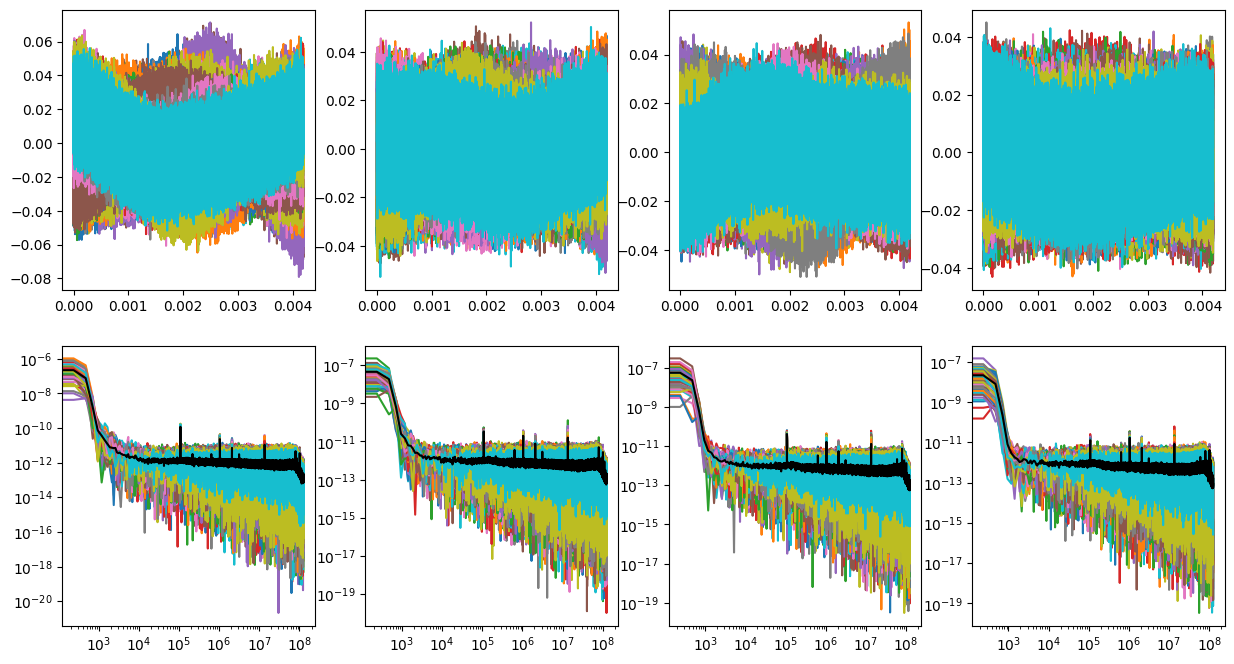

4846

In [5]:
fig, ax = plt.subplots(2, 4, figsize = (15, 8))
freq = 109e3
for i in range(0, 80):
    l.set_data(ind = i)
    l.get_data()[i].apply("detrend", mode = "linear", inplace = True)
    ax[0][i // 20].plot(l.get_data()[i].collection[0].t, l.get_data()[i].collection[0].x)
    ax[0][i // 20].plot(l.get_data()[i].collection[1].t, l.get_data()[i].collection[1].x)
    f, p0 = periodogram(l.get_data()[i].collection[0].x, l.get_data()[i].r, window = "hann", detrend = "linear")
    _, p1 = periodogram(l.get_data()[i].collection[1].x, l.get_data()[i].r, window = "hann", detrend = "linear")
    ax[1][i // 20].loglog(f, p0)
    ax[1][i // 20].loglog(f, p1)
    if i % 20 == 0:
        P = []
    p = np.array((p0 + p1) / 2)
    ax[1][i // 20].loglog(f, p)
    P.append(p)
    if i % 20 == 19:
        P = np.array(P)
        Pm = np.mean(P, axis = 0)
        std = np.std(P, axis = 0) 
        ax[1][i // 20].loglog(f, Pm, c = "k")

        df = f[1] - f[0]
        ix = np.argmin(np.abs(f - freq))
        ix += np.argmax(Pm[ix - 3 : ix + 4]) - 3
        pk = slice(ix - 4, ix + 5)
        nb = (np.abs(f - f[ix]) > 20 * df) & (np.abs(f - f[ix]) < 100 * df)
        assert nb.sum() > 50, f"only {nb.sum()} noise bins"
        Sn = np.mean(Pm[nb])
        Psig = np.sum(Pm[pk] - Sn) * df
        if Psig <= 0:
            print("no detection: Psig <", 3 * np.std(Pm[nb]) * np.sqrt(9) * df, "V^2")
        else:
            snrs = [np.sum(Pi[pk] - np.mean(Pi[nb])) / np.mean(Pi[nb]) for Pi in P]
            m, e = np.mean(snrs), np.std(snrs, ddof = 1) / np.sqrt(len(snrs))
            print(f"SNR in {df:.0f} Hz: {10 * np.log10(m):.1f} dB (+{10 * np.log10((m + e) / m):.1f} / -{10 * np.log10(m / (m - e)):.1f} dB)")
    
plt.show()
plt.close()
gc.collect()

In [30]:
path = "../../data/20261019/"
l = System("michelson", np.sort([f"{path}{f}/iter_{i}.tdms" for f in os.listdir(path) if os.path.isdir(os.path.join(path, f)) for i in range(0, 10)]), set_data = True, channel = "X")

In [88]:
voltages = []
for i in np.linspace(0, 10, 21):
    if 2 * i % 2 == 0:
        voltages.append(str(int(i)))
    else:
        voltages.append(str(i))
voltages = np.array(voltages)
print(voltages)

['0' '0.5' '1' '1.5' '2' '2.5' '3' '3.5' '4' '4.5' '5' '5.5' '6' '6.5' '7'
 '7.5' '8' '8.5' '9' '9.5' '10']


no detection: Psig < 3.1851863908083454e-09 V^2


/tmp/ipykernel_552/1138219901.py:52: RuntimeWarning: invalid value encountered in log10
  snr54.append(10 * np.log10(Psig / Sn))


no detection: Psig < 3.8891061626060895e-09 V^2


/tmp/ipykernel_552/1138219901.py:58: RuntimeWarning: invalid value encountered in log10
  snrno.append(10 * np.log10(Psig / Sn))


no detection: Psig < 3.5272027220774973e-09 V^2
no detection: Psig < 3.4640974556248138e-09 V^2
no detection: Psig < 3.5677938372406507e-09 V^2


/tmp/ipykernel_552/1138219901.py:55: RuntimeWarning: invalid value encountered in log10
  snr70.append(10 * np.log10(Psig / Sn))


no detection: Psig < 3.812543778607775e-09 V^2


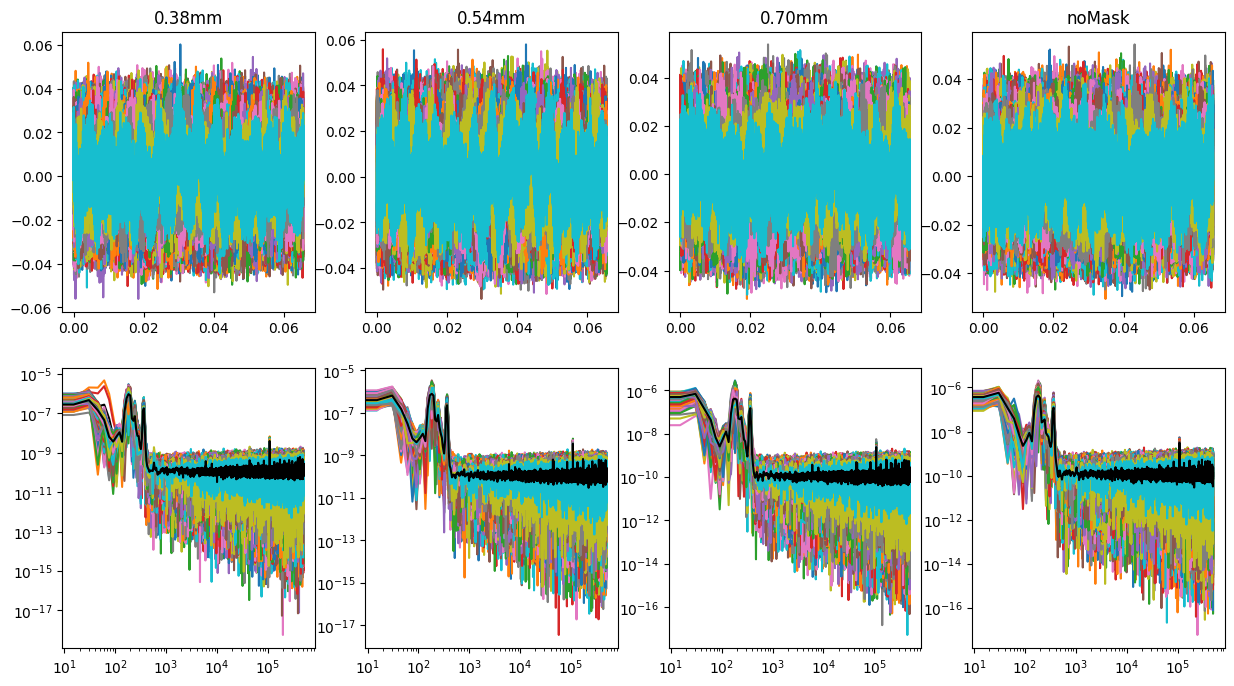

4445

In [9]:
snr38 = []
snr54 = []
snr70 = []
snrno = []

fig, ax = plt.subplots(2, 4, figsize = (15, 8))
freq = 109e3
for v in voltages:
    V = l.get_df()[np.array([f"Pout_{v}V" in i or ("0.70" in i and f"Pin_{v}V" in i) for i in l.get_df()])]
    for i in range(len(V)):
        idx = np.where(l.get_df() == V[i])[0][0]
        l.set_data(ind = idx)
        d = l.get_data()[idx]
        d.apply("detrend", mode = "linear", inplace = True)
        ax[0][i // 10].plot(d.collection[0].t, d.collection[0].x)
        ax[0][i // 10].plot(d.collection[1].t, d.collection[1].x)
        f, p0 = periodogram(d.collection[0].x, d.r, window = "hann", detrend = "linear")
        _, p1 = periodogram(d.collection[1].x, d.r, window = "hann", detrend = "linear")
        ax[1][i // 10].loglog(f, p0)
        ax[1][i // 10].loglog(f, p1)
        if i % 10 == 0:
            P = []
        p = np.array((p0 + p1) / 2)
        ax[1][i // 10].loglog(f, p)
        P.append(p)
        if i % 10 == 9:
            P = np.array(P)
            Pm = np.mean(P, axis = 0)
            std = np.std(P, axis = 0) 
            ax[1][i // 10].loglog(f, Pm, c = "k")
    
            df = f[1] - f[0]
            ix = np.argmin(np.abs(f - freq))
            ix += np.argmax(Pm[ix - 3 : ix + 4]) - 3
            pk = slice(ix - 4, ix + 5)
            nb = (np.abs(f - f[ix]) > 20 * df) & (np.abs(f - f[ix]) < 100 * df)
            assert nb.sum() > 50, f"only {nb.sum()} noise bins"
            Sn = np.mean(Pm[nb])
            Psig = np.sum(Pm[pk] - Sn) * df
            if Psig <= 0:
                print("no detection: Psig <", 3 * np.std(Pm[nb]) * np.sqrt(9) * df, "V^2")
            else:
                snrs = [np.sum(Pi[pk] - np.mean(Pi[nb])) / np.mean(Pi[nb]) for Pi in P]
                m, e = np.mean(snrs), np.std(snrs, ddof = 1) / np.sqrt(len(snrs))
                # print(f"SNR in {df:.0f} Hz: {10 * np.log10(Psig / (Sn * df)):.1f} dB,  C/N0: {10 * np.log10(Psig / Sn):.1f} dB-Hz")
                # print(f"SNR in {df:.0f} Hz: {10 * np.log10(m):.1f} dB (+{10 * np.log10((m + e) / m):.1f} / -{10 * np.log10(m / (m - e)):.1f} dB)")
            if i // 10 == 0:
                # snr38.append(10 * np.log10(m))
                snr38.append(10 * np.log10(Psig / Sn))
            if i // 10 == 1:
                # snr54.append(10 * np.log10(m))
                snr54.append(10 * np.log10(Psig / Sn))
            if i // 10 == 2:
                # snr70.append(10 * np.log10(m))
                snr70.append(10 * np.log10(Psig / Sn))
            if i // 10 == 3:
                # snrno.append(10 * np.log10(m))
                snrno.append(10 * np.log10(Psig / Sn))
            # print(l.get_df()[idx])
            # print()
            ax[0][i // 10].set_title(l.get_df()[idx][20:26])
    
plt.show()
plt.close()
gc.collect()

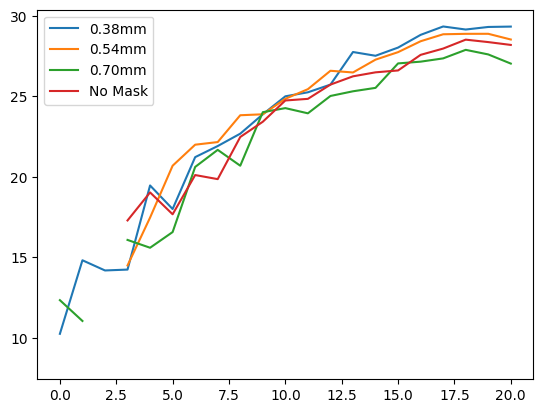

In [10]:
plt.plot(snr38, label = "0.38mm")
plt.plot(snr54, label = "0.54mm")
plt.plot(snr70, label = "0.70mm")
plt.plot(snrno, label = "No Mask")
plt.legend()
plt.show()

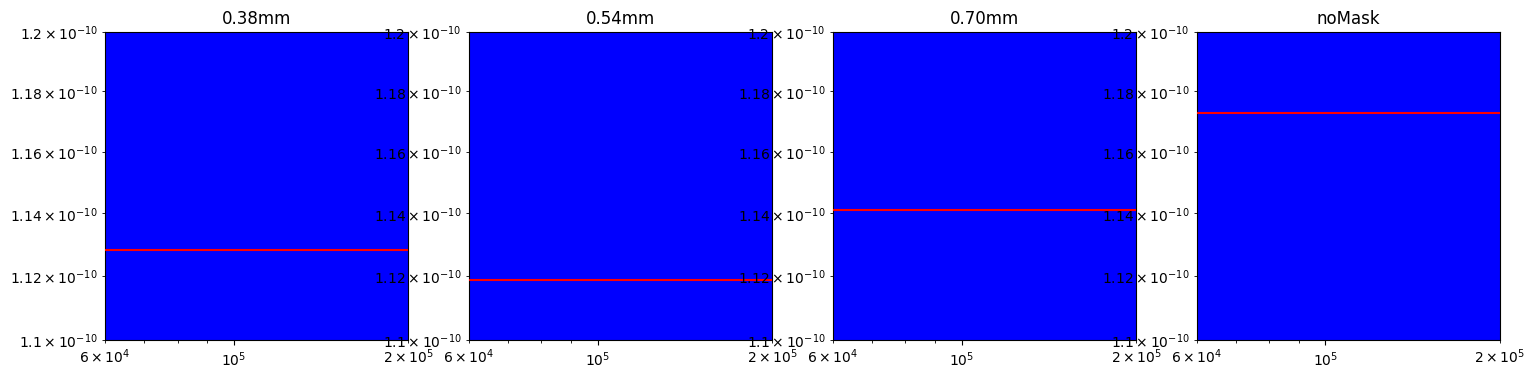

31806

In [98]:
freq = 109e3
fig, ax = plt.subplots(1, 4, figsize = (18, 4))
chosen = "10"
for v in voltages[np.array(["0" == i or chosen == i for i in voltages])]:
    V = l.get_df()[np.array([f"Pout_{v}V" in i or ("0.70" in i and f"Pin_{v}V" in i) for i in l.get_df()])]
    if v == chosen:
        c = "b"
    else:
        c = "k"
    for i in range(len(V)):
        idx = np.where(l.get_df() == V[i])[0][0]
        l.set_data(ind = idx)
        d = l.get_data()[idx]
        d.apply("detrend", mode = "linear", inplace = True)
        f, p0 = periodogram(d.collection[0].x, d.r, window = "hann", detrend = "linear")
        _, p1 = periodogram(d.collection[1].x, d.r, window = "hann", detrend = "linear")
        if i % 10 == 0:
            P = []
        p = np.array((p0 + p1) / 2)
        P.append(p)
        if i % 10 == 9:
            P = np.array(P)
            Pm = np.mean(P, axis = 0)
            if v == "0":
                ax[i // 10].axhline(np.mean(Pm[find_idx(f, find_nearest(f, 0.9e5)):find_idx(f, find_nearest(f, 1.1e5))]), c = "r", zorder = 10000)
            std = np.std(P, axis = 0)
            ax[i // 10].loglog(f, Pm, c = c)
            ax[i // 10].set_title(l.get_df()[idx][20:26])
            ax[i // 10].set_xlim(6e4, 2e5)
            ax[i // 10].set_ylim(1.1e-10, 1.2e-10)
plt.show()
plt.close()
gc.collect()

In [99]:
import sys
sys.path.append("../../fiber_optic_acoustics/")
import pandas as pd
import jax.numpy as jnp
import matplotlib.pyplot as plt
import jax
import laser
from jax import jit
import numpy as np
import os
import matplotlib.animation as animation
from quadax import quadgk
from laser import jax_hermite
from matplotlib import colormaps as cm
import numpy as np
from scipy.signal import periodogram, welch
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "cuda_async"
from analysis import System as syst
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx


def I_x(x, mode, waist, w, P_total, mux=0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0**n) * jax.scipy.special.factorial(n))
    
    norm_factor = (2.0 / (jnp.pi * w**2))**0.25
    field_x = norm_factor * norm_n * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w) * jnp.exp(-(x - mux)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_x**2)

def I_y(y, mode, waist, w, P_total, muy=0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_y = norm_factor * norm_m * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w) * jnp.exp(-(y - muy)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_y ** 2)

def dIy_dy_analytical(y, mode, waist, w, P_total, muy = 0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25

    y_scaled = jnp.sqrt(2) * (y - muy) / w
    Hm = jax_hermite(m, y_scaled)
    dH_dy = jnp.where(
        m > 0,
        2.0 * m * jax_hermite(m - 1, y_scaled) * (jnp.sqrt(2) / w),
        0.0,
    )

    field_y = norm_factor * norm_m * Hm * jnp.exp(-((y - muy) ** 2) / w ** 2)
    dfield_dy = norm_factor * norm_m * dH_dy * jnp.exp(
        -((y - muy) ** 2) / w ** 2
    ) - field_y * (2.0 * (y - muy) / w ** 2)

    return 2.0 * jnp.sqrt(P_total) * field_y * dfield_dy

def x_integ(bounds, mode, waist, w, P_total, mux = 0.0):
    integ, info = quadgk(I_x, bounds, args=(mode, waist, w, P_total, mux))
    return integ

def y_integ(bounds, mode, waist, w, P_total, muy = 0.0):
    integ, info = quadgk(I_y, bounds, args=(mode, waist, w, P_total, muy))
    return integ
    
def diffmap(mu, r, gap, mode, waist, w, targ_power, mux):
    x_power = x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux=mux)

    def diff(muy):
        if gap == 0:
            I_center = I_y(0.0, mode, waist, w, targ_power, muy=0.0)
            return x_power * (2.0 * I_center) * muy
        else:
            grad_at_edge = jnp.abs(
                dIy_dy_analytical(
                    gap / 2.0, mode, waist, w, targ_power, muy=0.0
                )
            )
            return x_power * (grad_at_edge * w) * muy

    return jax.vmap(diff)(mu)

def lsum(mu, r, gap, mode, waist, w, targ_power, mux):
    return x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([gap / 2, r]), mode, waist, w, targ_power, muy = mu) + x_integ(jnp.array([-r, r]), mode, waist, w, targ_power, mux = mux) * y_integ(jnp.array([-r, -gap / 2]), mode, waist, w, targ_power, muy = mu)

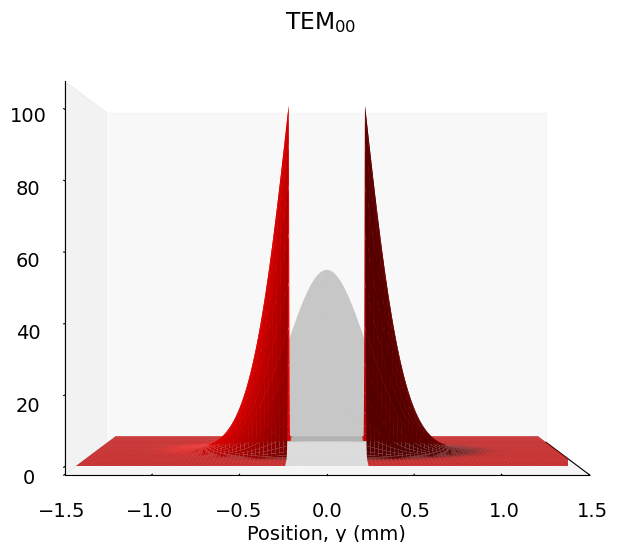

In [113]:
mode00 = jnp.array([0, 0], dtype=jnp.int32)
waist = 0.96 / 2
z = 0
w = waist * jnp.sqrt(1 + jnp.power(z / (jnp.pi * waist * 2 * 1 / 1064e-9), 2))
targ_power = 20

r = 3 * w
gap00 = waist
mux = 0
muy = 0

plt.rcParams.update({'font.size': 14})
fig = plt.figure(figsize = (6, 6))
ax1 = fig.add_subplot(1, 1, 1, projection='3d')
ax1.view_init(elev = 0, azim = 0, roll = 0)

x = jnp.linspace(-r, r, 1000)
y = jnp.linspace(-r, r, 1000)
y001 = jnp.linspace(-r, -gap00 / 2, 1000)
y002 = jnp.linspace(gap00 / 2, r, 1000)

ax1.plot_surface(x[jnp.newaxis, :], y[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, targ_power, mux) * I_y(y[:, jnp.newaxis], mode00, waist, w, targ_power, muy), color = "k", alpha = 0.1)

P = targ_power ** 2 / lsum(0, r, gap00, mode00, waist, w, targ_power, 0)

ax1.plot_surface(x[jnp.newaxis, :], y001[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, P, mux) * I_y(y001[:, jnp.newaxis], mode00, waist, w, P, muy), color = "r")
ax1.plot_surface(x[jnp.newaxis, :], y002[:, jnp.newaxis], I_x(x[jnp.newaxis, :], mode00, waist, w, P, mux) * I_y(y002[:, jnp.newaxis], mode00, waist, w, P, muy), color = "r")
ax1.grid(visible = False)
ax1.set_xticks(ticks = [])
ax1.set_title(r"TEM$_{\text{00}}$")
ax1.set_zlabel(r"Intensity, I ($\text{mW } / \text{ mm}^2$)")
ax1.set_ylabel("Position, y (mm)")
ax1.margins(0)
ax1.set_box_aspect(None, zoom = 1.5)

plt.tight_layout(pad = 2)

In [ ]:
def I_x(x, mode, waist, w, P_total, mux=0.0):
    n = mode[0]
    norm_n = 1.0 / jnp.sqrt((2.0**n) * jax.scipy.special.factorial(n))
    
    norm_factor = (2.0 / (jnp.pi * w**2))**0.25
    field_x = norm_factor * norm_n * jax_hermite(n, jnp.sqrt(2) * (x - mux) / w) * jnp.exp(-(x - mux)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_x**2)

def I_y(y, mode, waist, w, P_total, muy=0.0):
    m = mode[1]
    norm_m = 1.0 / jnp.sqrt((2.0 ** m) * jax.scipy.special.factorial(m))
    
    norm_factor = (2.0 / (jnp.pi * w ** 2)) ** 0.25
    field_y = norm_factor * norm_m * jax_hermite(m, jnp.sqrt(2) * (y - muy) / w) * jnp.exp(-(y - muy)**2 / w**2)
    
    return jnp.sqrt(P_total) * (field_y ** 2)